# EV Charging Session Clustering

Review 2: K-Means and Agglomerative Hierarchical Clustering.

### Objective
This notebook applies two unsupervised learning algorithms to the Electric Vehicle (EV) charging-session dataset:

1. **K-Means Clustering**
2. **Agglomerative Hierarchical Clustering**

The goal is to identify groups of charging sessions with similar connection times, charging durations, and energy-delivery patterns.

Both algorithms are evaluated using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. The notebook also includes a K-Means elbow curve, hierarchical dendrograms, PCA visualizations for both algorithms, a t-SNE visualization, and cluster profiles based on the original feature values.

### Rubric mapping
- **B1 — Implementation:** Fit both clustering algorithms and obtain cluster labels (Cells 7 and 10).
- **B2 — Evaluation:** Calculate all three internal metrics for both algorithms, inspect the K-Means elbow curve, and generate hierarchical dendrograms (Cells 6, 9, and 11).
- **B3 — Visualization:** Generate PCA plots for both algorithms and a t-SNE plot for K-Means (Cells 12–14).

### Features
The clustering features are `connectionTime_decimal`, `chargingDuration`, and `kWhDelivered`. Identifier or index columns are excluded from model fitting. `dayIndicator` is not used because this analysis focuses on connection time, charging duration, and delivered energy.

### Runtime and reproducibility
The notebook uses a reproducible sample of up to **100,000 charging records** for model fitting and evaluation, depending on the number of usable records in the CSV. The dendrograms use up to 500 rows and t-SNE uses up to 1,000 rows for visualization. Silhouette Score is estimated on a shared sample of up to 5,000 rows to manage computational cost; the other two internal metrics use all clustered observations. Results describe the selected sample and may differ from results obtained using the full dataset.

## Import required libraries and configure the runtime

This cell imports the libraries used for data handling, preprocessing, clustering, evaluation, and visualization. Pandas and NumPy support data processing, Matplotlib and Seaborn support plots, Scikit-learn provides preprocessing and machine-learning methods, and SciPy is used to construct hierarchical dendrograms.

A fixed random seed is used for reproducible sampling and randomized visualization. The environment settings limit CPU thread usage and may help avoid certain Windows or numerical-library thread warnings. If the relevant libraries have already been imported, restart the kernel and run this cell first.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"

import warnings
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import kneighbors_graph
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Load the EV charging dataset
This cell reads the EV charging dataset from a CSV file and checks that it has loaded correctly.

In [3]:
CSV_PATH = r"D:\5th Sem\ML\SYNTHETIC_EV_DATA.csv"  # Replace with your actual CSV filename or full path

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
display(df.head())


Dataset shape: (1965239, 4)

Column names:
['connectionTime_decimal', 'chargingDuration', 'kWhDelivered', 'dayIndicator']

Data types:
connectionTime_decimal    float64
chargingDuration          float64
kWhDelivered              float64
dayIndicator                int64
dtype: object


,connectionTime_decimal,chargingDuration,kWhDelivered,dayIndicator
0,15.332910,2.301191,11.469551,1
1,16.811495,4.941774,3.611695,1
2,21.151696,3.567173,14.455706,1
3,14.988554,3.089371,5.985330,1
4,15.078276,0.145047,1.274458,1


## Audit the dataset

This cell examines the dataset's dimensions, data types, missing values, duplicate rows, and descriptive statistics before clustering.

This audit helps identify data-quality issues that could affect preprocessing or clustering. Duplicate rows can influence cluster composition, and unusual values may affect distance-based methods. Potential outliers are not automatically removed because they may represent genuine EV charging sessions.

In [4]:
features = [
    "connectionTime_decimal",
    "chargingDuration",
    "kWhDelivered"
]

missing_features = [col for col in features if col not in df.columns]
if missing_features:
    raise ValueError(
        f"Required columns missing: {missing_features}. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Missing values by column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing Count"))

print("Duplicate rows:", df.duplicated().sum())
print("\nDescriptive statistics for clustering features:")
display(df[features].describe().T)

Missing values by column:


,Missing Count
connectionTime_decimal,0
chargingDuration,0
kWhDelivered,0
dayIndicator,0


Duplicate rows: 0

Descriptive statistics for clustering features:


,count,mean,std,min,25%,50%,75%,max
connectionTime_decimal,1965239.0,14.486311,6.427672,0.000007,14.247792,16.168053,18.041363,24.000000
chargingDuration,1965239.0,3.800781,3.387723,0.000014,1.443232,2.547029,5.436214,39.411059
kWhDelivered,1965239.0,9.437424,5.700660,0.000370,4.868768,9.174554,13.566734,62.537694


## Clean and select the clustering features

This cell converts the selected EV charging features to numeric values and removes rows where all selected features are missing or contain infinite values. Rows with individual missing feature values are retained for median imputation during preprocessing.

The analysis uses `connectionTime_decimal`, `chargingDuration`, and `kWhDelivered`. Identifier columns and `dayIndicator` are excluded so that clustering is based on the selected charging-session measurements rather than row identity or an additional indicator.

In [5]:
df_clean = df.copy()

for col in features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Replace infinite values with missing values so they can be imputed
df_clean[features] = df_clean[features].replace([np.inf, -np.inf], np.nan)

# Remove rows with no usable values among the selected features
df_clean = df_clean.dropna(subset=features, how="all").copy()

print("Rows before cleaning:", len(df))
print("Rows retained for clustering:", len(df_clean))
print("\nMissing values remaining in selected features:")
display(df_clean[features].isnull().sum().to_frame("Missing Count"))

Rows before cleaning: 1965239
Rows retained for clustering: 1965239

Missing values remaining in selected features:


,Missing Count
connectionTime_decimal,0
chargingDuration,0
kWhDelivered,0


## Exploratory data analysis (EDA)

This cell visualizes the distributions of the selected charging features and their pairwise correlations before clustering.

Histograms help reveal skewed distributions and long tails, while the correlation heatmap summarizes linear relationships between connection time, charging duration, and energy delivered. These plots support understanding of the data; they do not determine cluster labels or establish causal relationships.

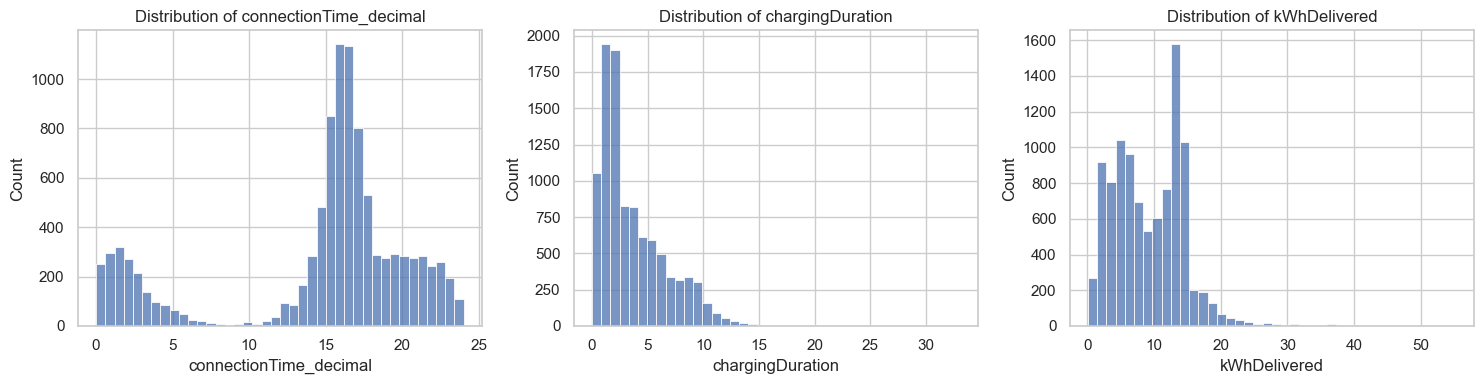

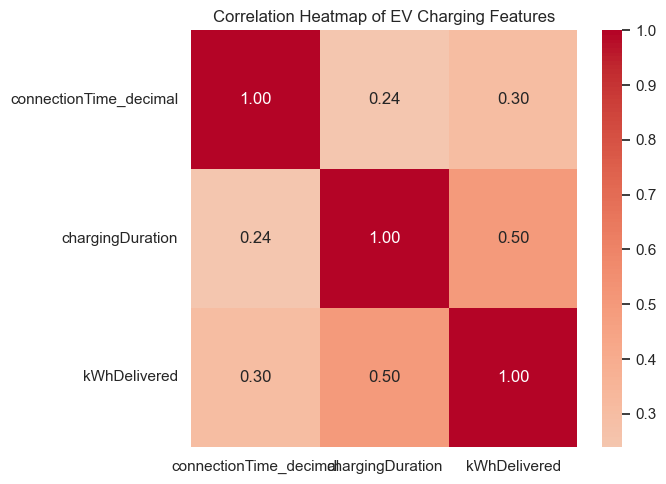

In [6]:
eda_data = df_clean[features].copy()
eda_data = eda_data.fillna(eda_data.median(numeric_only=True))
eda_data = eda_data.sample(n=min(10000, len(eda_data)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    sns.histplot(eda_data[col], bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    eda_data[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of EV Charging Features")
plt.tight_layout()
plt.show()

## Preprocess the data and inspect the K-Means elbow curve

This cell selects a reproducible sample of up to **100,000 charging records**, imputes missing values using the median, applies the Yeo–Johnson power transformation to reduce skewness, and standardizes the selected features. It then plots K-Means inertia for a range of cluster counts.

The transformation can reduce the influence of skewed feature distributions, while standardization places the features on comparable scales for distance-based clustering. Inertia generally decreases as the number of clusters increases; the elbow curve helps identify a candidate cluster count where additional clusters provide diminishing improvement.

The resulting standardized feature matrix is used by the later clustering and visualization cells.

Rows used for clustering: 100000
Features used: ['connectionTime_decimal', 'chargingDuration', 'kWhDelivered']
Missing values after preprocessing: 0


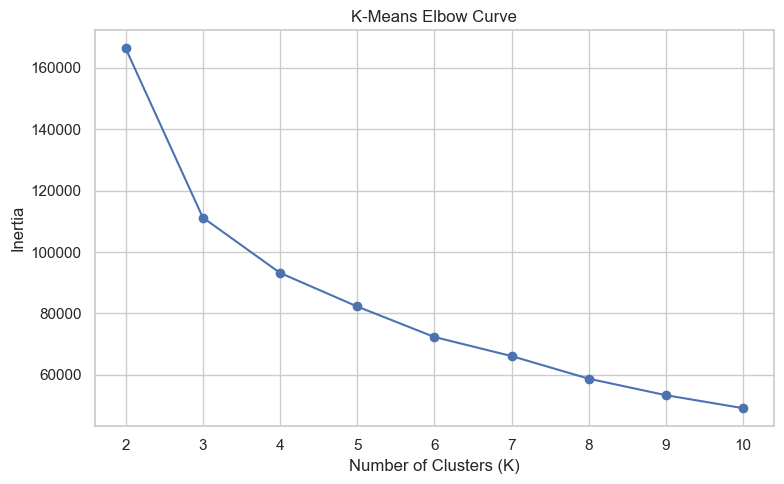

In [7]:
SAMPLE_SIZE = 100000
sample = df_clean.sample(n=min(SAMPLE_SIZE, len(df_clean)), random_state=RANDOM_STATE).copy()
X_original_sample = sample[features].copy()

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X_original_sample)

print("Rows used for clustering:", X_scaled.shape[0])
print("Features used:", features)
print("Missing values after preprocessing:", int(np.isnan(X_scaled).sum()))

k_values = range(2, min(10, len(X_scaled) - 1) + 1)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5, max_iter=100)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()